In [1]:
from backend.utils.gmsh_function import *
from backend.utils.file_path import *
from backend.src.radiation_algorithm.radiation_algorithm import *
from loop_antenna_gmsh import create_loop_antenna_geometry

from backend.efield.efield1 import *
from backend.efield.efield2 import radiation_intensity_distribution_over_sphere_surface
from backend.efield.efield3 import antenna_directivity_pattern

from backend.utils.frequency_sweep import *

## Center-fed normal-mode helical (loop) antenna

Two helical ribbons of radius `a`, strip width `2w` and pitch `R`, stacked
along z and separated by a small feed gap `d` at the middle -- the coil and
its straight-wire equivalent are the classic normal-mode helix sketch (helix
much smaller than the wavelength).

In [2]:
name = "loop_antenna"
path = setup_save_file_paths(name)

In [ ]:
mm = 1e-3
cm = 1e-2

a = 0.5 * cm          # helix radius (2a = coil diameter)
w = 0.2 * mm        # ribbon half-width (2w = wire/strip width)
pitch = 6 * mm      # height gained per turn (R)
n_turns_lower = 3
n_turns_upper = 3

gmsh.initialize()
gmsh.model.add("loop_antenna")
setup_performance_config()

total_height = create_loop_antenna_geometry(
    a, w, pitch, n_turns_lower, n_turns_upper, segments_per_turn=12)

initialize_mesh = 8*w

generate_and_save_mesh(path, initialize_mesh)

# gmsh.fltk.run()

gmsh.finalize()

print(f"Total height: {total_height * 1000:.2f} mm")

[PERFORMANCE] Gmsh configured to utilize 16 threads.
Geometry file saved in data/gmsh_files/loop_antenna.brep successfully
--- Starting Mesh Optimization (Dim: 2) ---
--- Optimization Complete ---
Mesh file saved in data/gmsh_files/loop_antenna.msh successfully
Total height: 36.00 mm


In [4]:
frequency = 200e6  # normal-mode regime: total_height << wavelength (~1.5 m)
excitation_unit_vector = 'x'   # helix tangent direction at the feed (theta=0 -> dy/dtheta dominates)
gap_width = 1.5*initialize_mesh
feed_point = np.array([a, 0, total_height/2.0])

_ = radiation_algorithm(path, frequency, feed_point,
                        excitation_unit_vector=excitation_unit_vector, gap_width=gap_width,
                        show=True, save_image=True)

Number of points: 290
Number of triangles: 288
Number of edges: 287
[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (287x287 edges).
Total input power P_in = 0.5*Re(V·I*) = 3.675572e-07 W
Port 0: P_in = 3.6756e-07 W  |  Q_in = -1.1613e-06 VAR  |  Z_in = 123871.9446-391360.1798j Ohm



Image saved in PDF format: data/fig_image/loop_antenna_antenna_surface_current_in_radiation_mode.pdf



In [5]:
print("Calculating radiation intensity distribution over sphere surface...")
radiation_intensity_distribution_over_sphere_surface(path, save_image=True)

Calculating radiation intensity distribution over sphere surface...
Hollow sphere loaded: 5150 points, 10296 triangles.

[Antenna Results]
  Total Radiated Power : 3.3070434793196424e-13 W
  Gain : 1.5057 (1.78 dBi)

[Power Budget]
  P_in  (0.5*Re(V·I*)) = 3.675572e-07 W
  P_rad (sphere integ.) = 3.307043e-13 W
  Raw efficiency       = 0.0001 %
  Port 0: Z_in = 123871.9446-391360.1798j Ω  |  R_in = 123871.9446 Ω
  Total Efficiency     = 0.00 %
Data saved successfully to data/antennas_gain_power/loop_antenna_gain_power.mat


Image saved: data/fig_image/radiation_pattern_loop_antenna.pdf


Generating antenna directivity pattern...
Data loaded from data/antennas_gain_power/loop_antenna_gain_power.mat


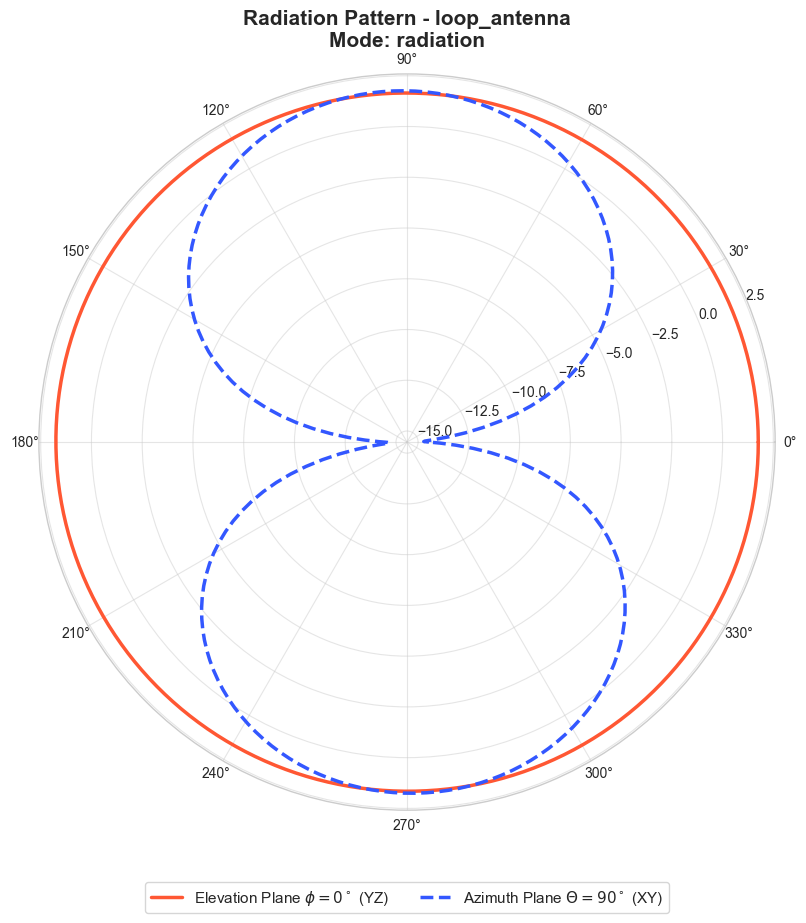

In [6]:
print("Generating antenna directivity pattern...")
antenna_directivity_pattern(path, mode='radiation', save_image=True)

freq_start = 150e6
freq_stop  = 250e6
frequency_sweep(path, freq_start, freq_stop, feed_point, voltage_amplitude=1,
                excitation_unit_vector=excitation_unit_vector, gap_width=gap_width,
                n_points=5, show=False)
plot_s_parameters(path, interpolation_threshold=0, save_pdf=True, save_folder="data/fig_image/")